# 1. Test
Just testing Jupyter

In [3]:
print("hello world")

hello world


# 2. Import the needed tools

In [89]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import json
import os

# 3. Problem Definition
## Cross Platform Robustness and Fairness of Mental Health Text Classifiers
This project investigates how machine learning models trained on mental health related text from one social media platform such as Reddit perform when applied to another such as Twitter. It combines publicly available datasets from at least two platforms and evaluates five different models including Logistic Regression, Support Vector Machine, Random Forest, BiLSTM and BERT or RoBERTa with domain adaptation. Quantitative metrics are complemented by qualitative analyses using SHAP or LIME to identify biased features and interpret model behavior. A lightweight web application using Streamlit or Gradio allows users to input text and view model predictions with explanations. This approach directly addresses a gap in cross domain and fairness aware mental health natural language processing and is feasible because several large anonymized datasets are already publicly available.

# 4.DATA 
This is the data we are going to use.

## ADDICTION SUBREDDIT 2019

In [151]:
df = pd.read_csv("addiction_2019_features_tfidf_256.csv")

The following shows the dataset for the addiction subreddit.

In [152]:
df.head(10)

,subreddit,author,date,post,automated_readability_index,coleman_liau_index,flesch_kincaid_grade_level,flesch_reading_ease,gulpease_index,gunning_fog_index,...,tfidf_wish,tfidf_without,tfidf_wonder,tfidf_work,tfidf_worri,tfidf_wors,tfidf_would,tfidf_wrong,tfidf_x200b,tfidf_year
0,addiction,Lillie1990,2019/01/01,Quitting coke and need advice So I’m 20. I’ve ...,2.315272,4.091255,3.580870,89.872283,76.880435,6.773913,...,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.090840,0.0,0.0,0.000000
1,addiction,P3nw00dx,2019/01/01,I am addicted to sleep I really really like to...,1.591231,2.547960,3.821538,90.818462,77.000000,7.661538,...,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
2,addiction,throwaway146900,2019/01/01,Addicted to scratching my balls This may sound...,2.829911,4.762222,3.912143,87.370000,75.875000,6.571429,...,0.000000,0.270254,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.180540
3,addiction,deeseypieces14,2019/01/01,Who else has lost their kids because their add...,2.996143,5.849158,2.656786,91.599464,80.714286,4.642857,...,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4,addiction,asdfderp1009,2019/01/01,Please Read I’ve been suffering addiction to k...,2.935333,5.666867,4.505000,79.090833,79.727273,8.030303,...,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.159984
5,addiction,wizardslashmagi,2019/01/01,I’ve had enough I’ve struggled on and off with...,3.246629,5.124602,4.268322,85.510315,74.538462,6.983683,...,0.098561,0.082620,0.0,0.000000,0.000000,0.000000,0.060885,0.0,0.0,0.165581
6,addiction,fuckingburner1232,2019/01/01,beginning of stimulant addiction so i have don...,5.930565,5.247064,7.513422,74.018372,66.751938,11.712514,...,0.000000,0.171495,0.0,0.000000,0.180672,0.000000,0.000000,0.0,0.0,0.229131
7,addiction,Girl-Here,2019/01/01,7 years in rehab. 1 major bender. 32 days in t...,4.881687,6.857808,5.437485,78.419834,70.369151,8.760892,...,0.080456,0.000000,0.0,0.050935,0.000000,0.000000,0.049701,0.0,0.0,0.225276
8,addiction,bryanramirez,2019/01/01,Addiction and i want to stop Ok i have a mastu...,3.111905,4.623755,5.806540,75.874571,74.079365,10.119365,...,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
9,addiction,deebeezkneez,2019/01/02,Recovering parents: Should I adopt the grandch...,8.642073,7.526479,8.120606,73.273636,61.533333,10.670707,...,0.000000,0.000000,0.0,0.000000,0.000000,0.117507,0.245731,0.0,0.0,0.074253


In [153]:
print(df.describe())

       automated_readability_index  coleman_liau_index  \
count                  1257.000000         1257.000000   
mean                      4.122960            5.789481   
std                       5.401076            6.336073   
min                      -6.183125          -10.061270   
25%                       1.676111            3.529429   
50%                       3.246629            4.886473   
75%                       5.231818            6.330463   
max                     113.277143          143.768291   

       flesch_kincaid_grade_level  flesch_reading_ease  gulpease_index  \
count                 1257.000000          1257.000000     1257.000000   
mean                     4.768566            82.461576       75.438502   
std                      2.721180            16.423389       15.275582   
min                     -1.640000          -235.355714     -146.714286   
25%                      3.176566            79.114500       69.000000   
50%                      4.351345

In [154]:
print(df.isnull().sum())

subreddit                      0
author                         0
date                           0
post                           0
automated_readability_index    0
                              ..
tfidf_wors                     0
tfidf_would                    0
tfidf_wrong                    0
tfidf_x200b                    0
tfidf_year                     0
Length: 350, dtype: int64


In [155]:
print(df.shape)
num_posts = len(df)
print("Number of posts:", num_posts)

(1257, 350)
Number of posts: 1257


Checking all the columns names:

In [169]:
print(df.columns.tolist())

['subreddit', 'author', 'date', 'post', 'automated_readability_index', 'coleman_liau_index', 'flesch_kincaid_grade_level', 'flesch_reading_ease', 'gulpease_index', 'gunning_fog_index', 'lix', 'smog_index', 'wiener_sachtextformel', 'n_chars', 'n_long_words', 'n_monosyllable_words', 'n_polysyllable_words', 'n_sents', 'n_syllables', 'n_unique_words', 'n_words', 'sent_neg', 'sent_neu', 'sent_pos', 'sent_compound', 'economic_stress_total', 'isolation_total', 'substance_use_total', 'guns_total', 'domestic_stress_total', 'suicidality_total', 'punctuation', 'liwc_1st_pers', 'liwc_2nd_pers', 'liwc_3rd_pers', 'liwc_achievement', 'liwc_adverbs', 'liwc_affective_processes', 'liwc_anger', 'liwc_anxiety', 'liwc_articles_article', 'liwc_assent', 'liwc_auxiliary_verbs', 'liwc_biological', 'liwc_body', 'liwc_causation', 'liwc_certainty', 'liwc_cognitive', 'liwc_common_verbs', 'liwc_conjunctions', 'liwc_death', 'liwc_discrepancy', 'liwc_exclusive', 'liwc_family', 'liwc_feel', 'liwc_fillers', 'liwc_frien


Top 10 words by average TF-IDF score:
tfidf_addict    0.214672
tfidf_drug      0.076950
tfidf_day       0.067528
tfidf_get       0.065629
tfidf_use       0.061273
tfidf_help      0.060815
tfidf_year      0.059968
tfidf_know      0.054922
tfidf_time      0.053812
tfidf_want      0.053110
dtype: float64


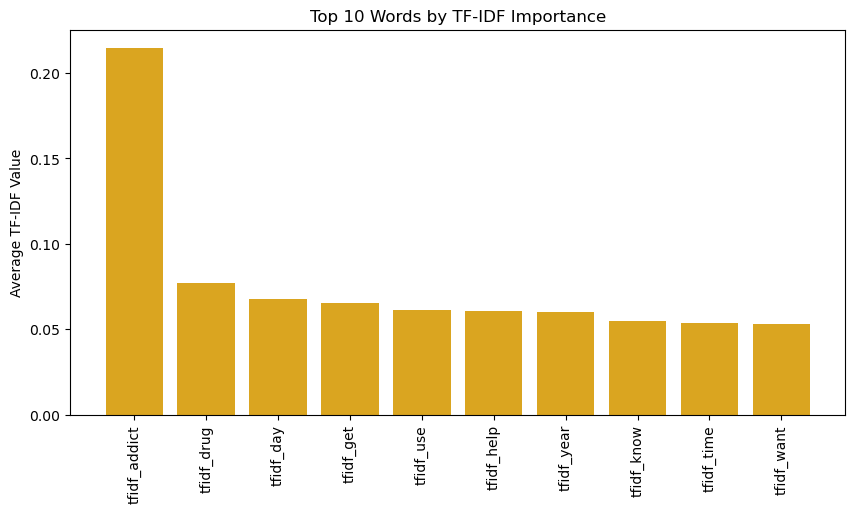

In [157]:
tfidf_cols = [col for col in dr.columns if col.startswith('tfidf_')]

tfidf_mean = df[tfidf_cols].mean().sort_values(ascending=False)

print("\nTop 10 words by average TF-IDF score:")
print(tfidf_mean.head(10))

top_tfidf = tfidf_mean.head(10)
plt.figure(figsize=(10,5))
plt.bar(top_tfidf.index, top_tfidf.values, color='goldenrod')
plt.title("Top 10 Words by TF-IDF Importance")
plt.xticks(rotation=90)
plt.ylabel("Average TF-IDF Value")
plt.show()



Correlation matrix of readability metrics:
                             automated_readability_index  coleman_liau_index  \
automated_readability_index                     1.000000            0.963171   
coleman_liau_index                              0.963171            1.000000   
flesch_kincaid_grade_level                      0.910058            0.808945   
flesch_reading_ease                            -0.923830           -0.911200   
gulpease_index                                 -0.825918           -0.776244   
gunning_fog_index                               0.685659            0.545051   
smog_index                                      0.580841            0.485025   

                             flesch_kincaid_grade_level  flesch_reading_ease  \
automated_readability_index                    0.910058            -0.923830   
coleman_liau_index                             0.808945            -0.911200   
flesch_kincaid_grade_level                     1.000000            -0.93123

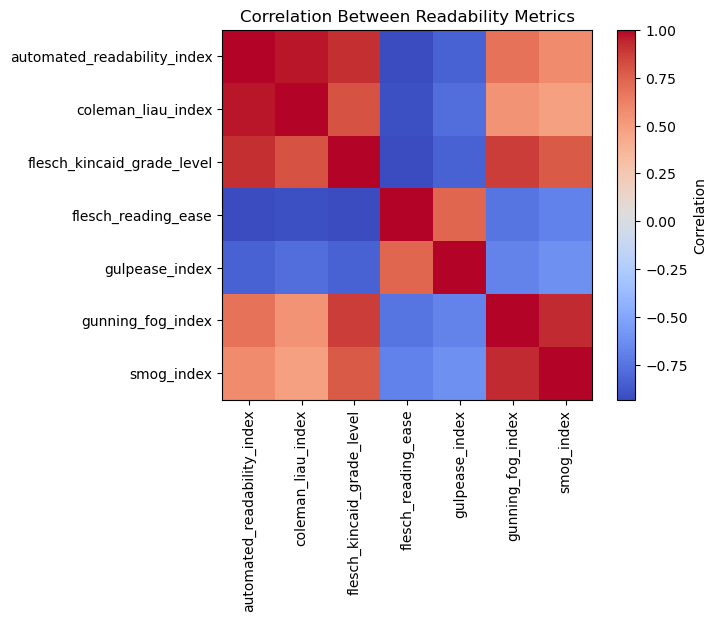

In [158]:
corr_matrix = df[read_cols].corr()
print("\nCorrelation matrix of readability metrics:")
print(corr_matrix)

plt.imshow(corr_matrix, cmap='coolwarm', interpolation='nearest')
plt.colorbar(label='Correlation')
plt.xticks(range(len(read_cols)), read_cols, rotation=90)
plt.yticks(range(len(read_cols)), read_cols)
plt.title("Correlation Between Readability Metrics")
plt.show()


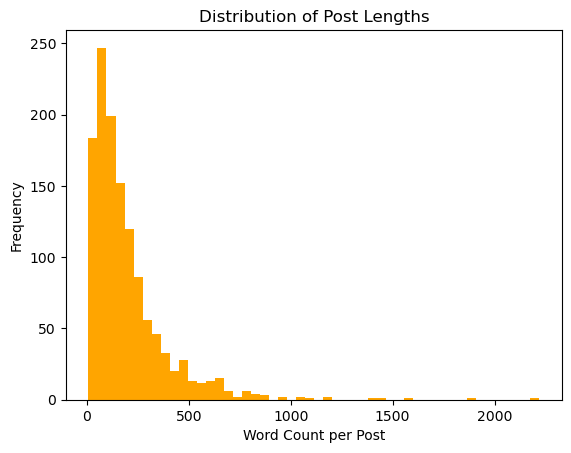

Average post length: 196.52028639618138


In [170]:
plt.hist(df['n_words'], bins=50, color='orange')
plt.title("Distribution of Post Lengths")
plt.xlabel("Word Count per Post")
plt.ylabel("Frequency")
plt.show()

print("Average post length:", df['n_words'].mean())


## MENTAL HEALTH SUBREDDIT 2019

In [121]:
df1 = pd.read_csv("mentalhealth_2019_features_tfidf_256.csv")

In [128]:
print(df1.describe())
print(df1.isnull().sum())

       automated_readability_index  coleman_liau_index  \
count                  9533.000000         9533.000000   
mean                      4.468029            5.889607   
std                       5.061626            5.810906   
min                      -5.682200           -8.905570   
25%                       2.269368            4.028024   
50%                       3.859834            5.278247   
75%                       5.702565            6.654541   
max                     178.390000          223.756118   

       flesch_kincaid_grade_level  flesch_reading_ease  gulpease_index  \
count                 9533.000000          9533.000000     9533.000000   
mean                     5.206089            80.970746       73.190695   
std                      2.572669            15.111080       12.483215   
min                     -2.035000          -298.310000     -256.000000   
25%                      3.706285            76.436745       67.769841   
50%                      4.911569

In [129]:
print(df1.shape)
num_posts = len(df1)
print("Number of posts:", num_posts)

(9533, 350)
Number of posts: 9533


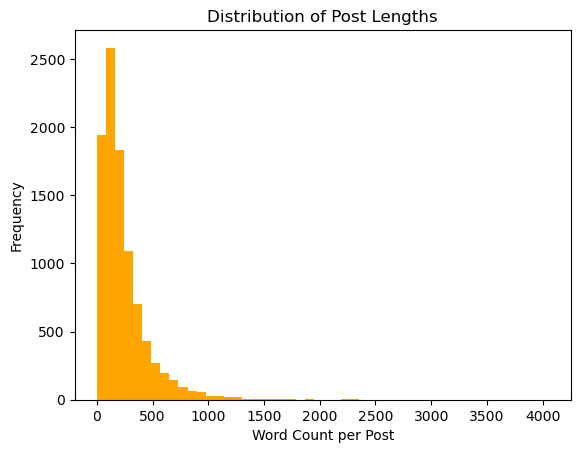

Average post length: 237.86426098814644


In [144]:
plt.hist(df1['n_words'], bins=50, color='orange')
plt.title("Distribution of Post Lengths")
plt.xlabel("Word Count per Post")
plt.ylabel("Frequency")
plt.show()

print("Average post length:", df1['n_words'].mean())



Top 10 words by average TF-IDF score:
tfidf_feel       0.096978
tfidf_like       0.078385
tfidf_mental     0.064661
tfidf_get        0.063512
tfidf_know       0.063400
tfidf_help       0.057776
tfidf_want       0.056422
tfidf_go         0.055123
tfidf_depress    0.054477
tfidf_time       0.051589
dtype: float64


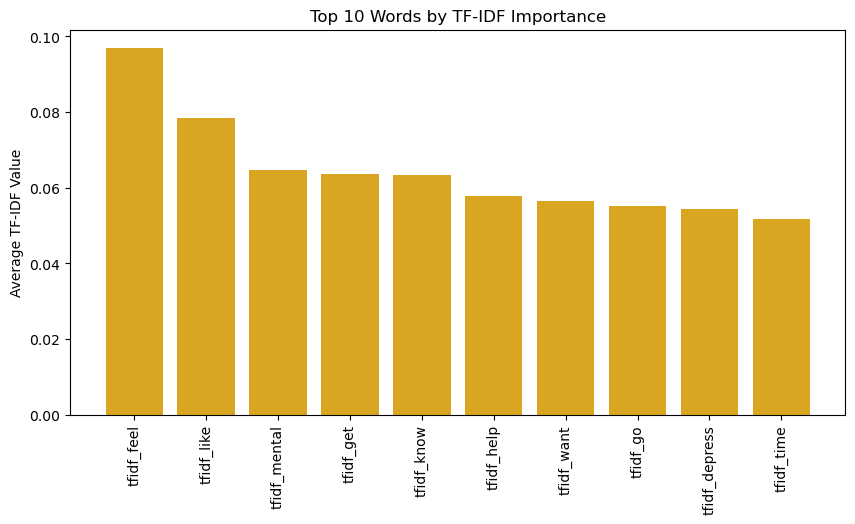

In [130]:
tfidf_cols = [col for col in df1.columns if col.startswith('tfidf_')]

tfidf_mean = df1[tfidf_cols].mean().sort_values(ascending=False)

print("\nTop 10 words by average TF-IDF score:")
print(tfidf_mean.head(10))

top_tfidf = tfidf_mean.head(10)
plt.figure(figsize=(10,5))
plt.bar(top_tfidf.index, top_tfidf.values, color='goldenrod')
plt.title("Top 10 Words by TF-IDF Importance")
plt.xticks(rotation=90)
plt.ylabel("Average TF-IDF Value")
plt.show()



Correlation matrix of readability metrics:
                             automated_readability_index  coleman_liau_index  \
automated_readability_index                     1.000000            0.956718   
coleman_liau_index                              0.956718            1.000000   
flesch_kincaid_grade_level                      0.908572            0.786341   
flesch_reading_ease                            -0.928726           -0.911384   
gulpease_index                                 -0.889459           -0.806597   
gunning_fog_index                               0.569784            0.382346   
smog_index                                      0.496709            0.361970   

                             flesch_kincaid_grade_level  flesch_reading_ease  \
automated_readability_index                    0.908572            -0.928726   
coleman_liau_index                             0.786341            -0.911384   
flesch_kincaid_grade_level                     1.000000            -0.92625

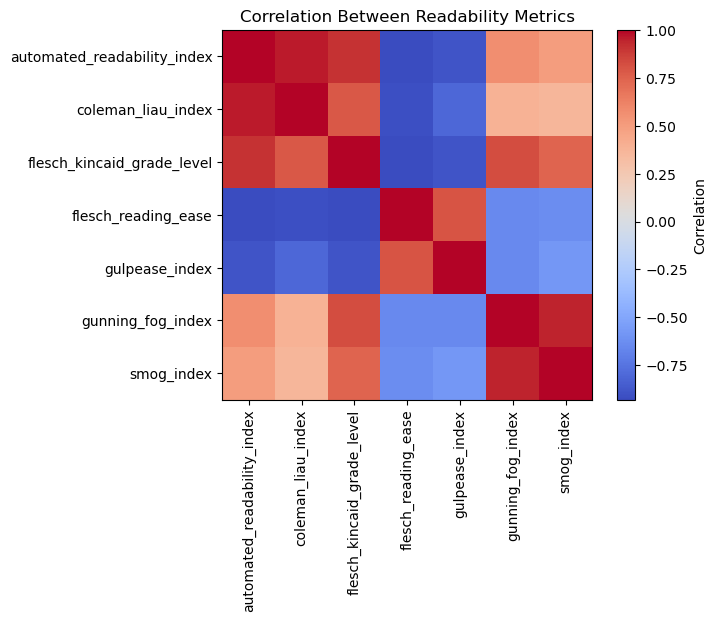

In [137]:
corr_matrix = df1[read_cols].corr()
print("\nCorrelation matrix of readability metrics:")
print(corr_matrix)

plt.imshow(corr_matrix, cmap='coolwarm', interpolation='nearest')
plt.colorbar(label='Correlation')
plt.xticks(range(len(read_cols)), read_cols, rotation=90)
plt.yticks(range(len(read_cols)), read_cols)
plt.title("Correlation Between Readability Metrics")
plt.show()


## ADHD SUBREDDIT 2019

In [138]:
df3 = pd.read_csv("adhd_2019_features_tfidf_256.csv")

In [173]:
print(df3.describe())
print(df3.isnull().sum())

       automated_readability_index  coleman_liau_index  \
count                 10223.000000        10223.000000   
mean                      4.495216            5.952892   
std                       3.228813            3.198931   
min                      -6.992000          -11.172133   
25%                       2.538815            4.416761   
50%                       4.187500            5.733180   
75%                       5.988489            7.016461   
max                      65.844000           84.523583   

       flesch_kincaid_grade_level  flesch_reading_ease  gulpease_index  \
count                10223.000000         10223.000000    10223.000000   
mean                     5.363987            79.599805       73.541929   
std                      2.193488            11.289990       10.775457   
min                     -2.815000          -141.150000      -48.333333   
25%                      3.933709            74.275693       67.214286   
50%                      5.191580

In [147]:
print(df3.shape)
num_posts = len(df3)
print("Number of posts:", num_posts)

(10223, 350)
Number of posts: 10223


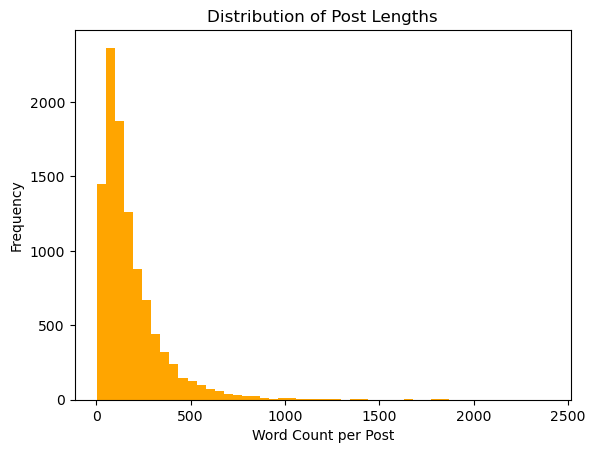

Average post length: 183.8325344810721


In [148]:
plt.hist(df3['n_words'], bins=50, color='orange')
plt.title("Distribution of Post Lengths")
plt.xlabel("Word Count per Post")
plt.ylabel("Frequency")
plt.show()

print("Average post length:", df3['n_words'].mean())



Top 10 words by average TF-IDF score:
tfidf_adhd     0.171457
tfidf_get      0.071245
tfidf_take     0.063267
tfidf_like     0.062595
tfidf_work     0.061374
tfidf_feel     0.053875
tfidf_time     0.052803
tfidf_medic    0.052461
tfidf_thing    0.048783
tfidf_med      0.048057
dtype: float64


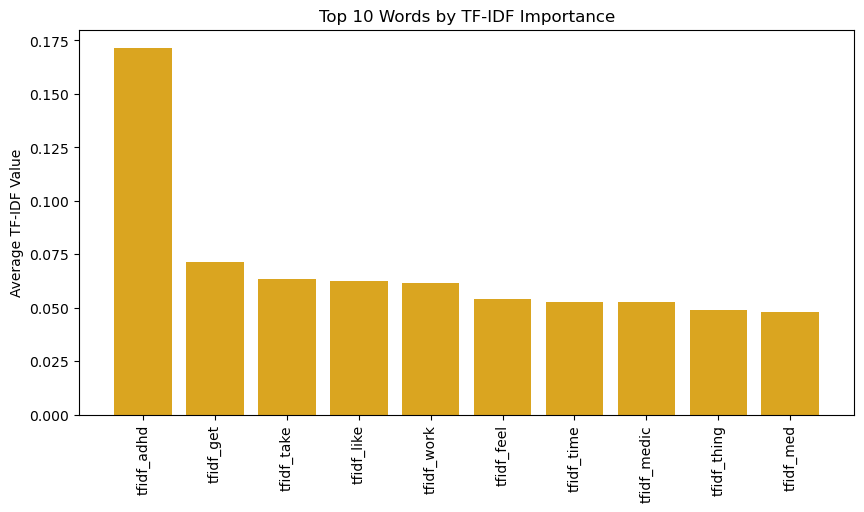

In [177]:
tfidf_cols = [col for col in df3.columns if col.startswith('tfidf_')]

tfidf_mean = df3[tfidf_cols].mean().sort_values(ascending=False)

print("\nTop 10 words by average TF-IDF score:")
print(tfidf_mean.head(10))

top_tfidf = tfidf_mean.head(10)
plt.figure(figsize=(10,5))
plt.bar(top_tfidf.index, top_tfidf.values, color='goldenrod')
plt.title("Top 10 Words by TF-IDF Importance")
plt.xticks(rotation=90)
plt.ylabel("Average TF-IDF Value")
plt.show()



Correlation matrix of readability metrics:
                             automated_readability_index  coleman_liau_index  \
automated_readability_index                     1.000000            0.891553   
coleman_liau_index                              0.891553            1.000000   
flesch_kincaid_grade_level                      0.914300            0.722795   
flesch_reading_ease                            -0.860283           -0.853303   
gulpease_index                                 -0.807572           -0.671417   
gunning_fog_index                               0.766303            0.540920   
smog_index                                      0.676447            0.540568   

                             flesch_kincaid_grade_level  flesch_reading_ease  \
automated_readability_index                    0.914300            -0.860283   
coleman_liau_index                             0.722795            -0.853303   
flesch_kincaid_grade_level                     1.000000            -0.90068

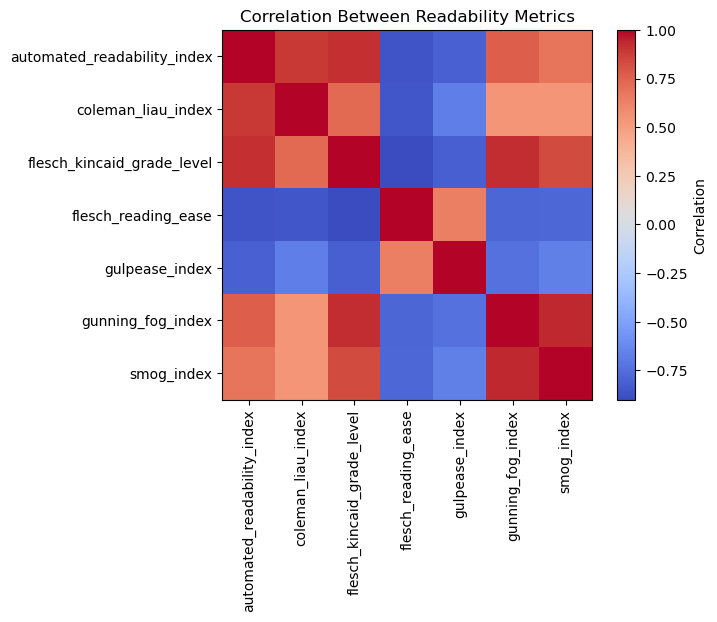

In [150]:
corr_matrix = df3[read_cols].corr()
print("\nCorrelation matrix of readability metrics:")
print(corr_matrix)

plt.imshow(corr_matrix, cmap='coolwarm', interpolation='nearest')
plt.colorbar(label='Correlation')
plt.xticks(range(len(read_cols)), read_cols, rotation=90)
plt.yticks(range(len(read_cols)), read_cols)
plt.title("Correlation Between Readability Metrics")
plt.show()

## ALCOHOLISM SUBREDDIT 2019

In [172]:
df4 = pd.read_csv("alcoholism_2019_features_tfidf_256.csv")

In [174]:
print(df4.describe())
print(df4.isnull().sum())

       automated_readability_index  coleman_liau_index  \
count                   942.000000          942.000000   
mean                      3.265905            4.958765   
std                       4.428311            5.119662   
min                      -4.771000           -3.680449   
25%                       1.360907            3.244538   
50%                       3.027104            4.644621   
75%                       4.465074            5.947446   
max                      78.181250           98.595628   

       flesch_kincaid_grade_level  flesch_reading_ease  gulpease_index  \
count                  942.000000           942.000000      942.000000   
mean                     4.285942            85.191070       76.993546   
std                      2.274879            13.250828       12.456351   
min                     -1.056667          -129.645000      -84.750000   
25%                      2.920316            80.075625       70.786213   
50%                      4.206996

In [175]:
print(df4.shape)
num_posts = len(df4)
print("Number of posts:", num_posts)

(942, 350)
Number of posts: 942


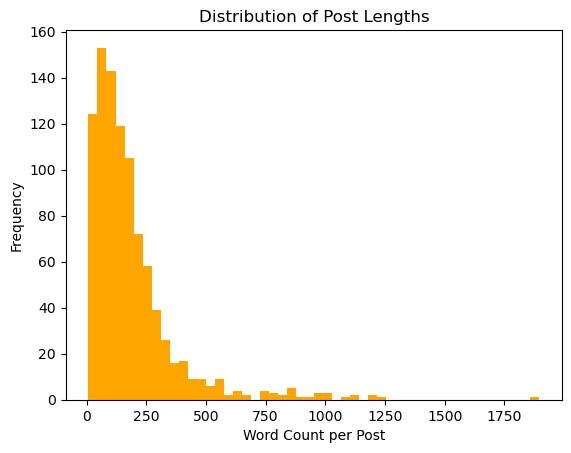

Average post length: 185.97133757961782


In [176]:
plt.hist(df4['n_words'], bins=50, color='orange')
plt.title("Distribution of Post Lengths")
plt.xlabel("Word Count per Post")
plt.ylabel("Frequency")
plt.show()

print("Average post length:", df4['n_words'].mean())


Top 10 words by average TF-IDF score:
tfidf_drink      0.256658
tfidf_alcohol    0.167938
tfidf_day        0.074951
tfidf_get        0.056835
tfidf_go         0.056533
tfidf_year       0.055638
tfidf_feel       0.053029
tfidf_know       0.052277
tfidf_want       0.050954
tfidf_time       0.050788
dtype: float64


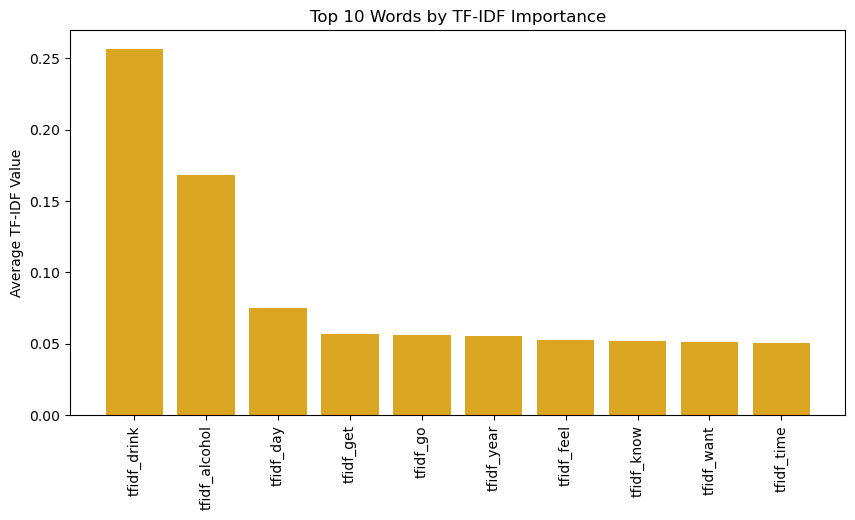

In [178]:
tfidf_cols = [col for col in df4.columns if col.startswith('tfidf_')]

tfidf_mean = df4[tfidf_cols].mean().sort_values(ascending=False)

print("\nTop 10 words by average TF-IDF score:")
print(tfidf_mean.head(10))

top_tfidf = tfidf_mean.head(10)
plt.figure(figsize=(10,5))
plt.bar(top_tfidf.index, top_tfidf.values, color='goldenrod')
plt.title("Top 10 Words by TF-IDF Importance")
plt.xticks(rotation=90)
plt.ylabel("Average TF-IDF Value")
plt.show()



Correlation matrix of readability metrics:
                             automated_readability_index  coleman_liau_index  \
automated_readability_index                     1.000000            0.965588   
coleman_liau_index                              0.965588            1.000000   
flesch_kincaid_grade_level                      0.897889            0.796219   
flesch_reading_ease                            -0.912061           -0.899309   
gulpease_index                                 -0.886328           -0.805047   
gunning_fog_index                               0.643323            0.503662   
smog_index                                      0.541730            0.459283   

                             flesch_kincaid_grade_level  flesch_reading_ease  \
automated_readability_index                    0.897889            -0.912061   
coleman_liau_index                             0.796219            -0.899309   
flesch_kincaid_grade_level                     1.000000            -0.93211

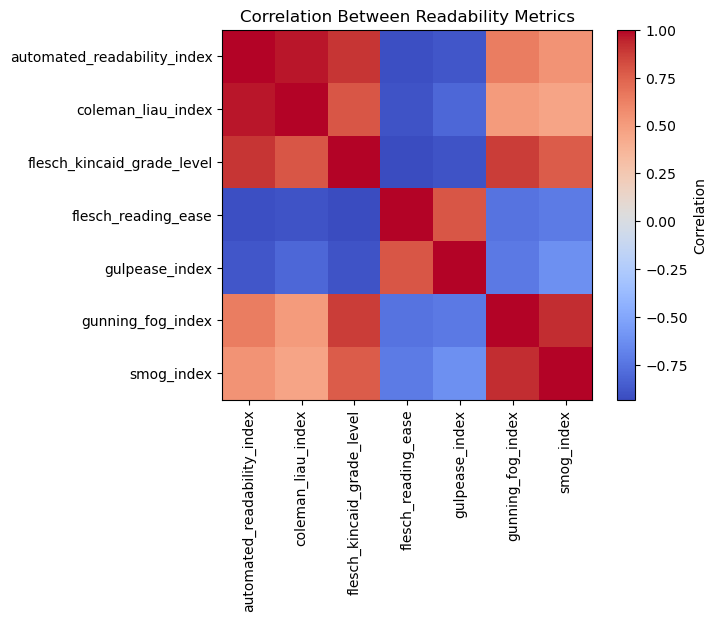

In [180]:
corr_matrix = df4[read_cols].corr()
print("\nCorrelation matrix of readability metrics:")
print(corr_matrix)

plt.imshow(corr_matrix, cmap='coolwarm', interpolation='nearest')
plt.colorbar(label='Correlation')
plt.xticks(range(len(read_cols)), read_cols, rotation=90)
plt.yticks(range(len(read_cols)), read_cols)
plt.title("Correlation Between Readability Metrics")
plt.show()

## ANXIETY SUBREDDIT 2019

In [183]:
df5 = pd.read_csv("anxiety_2019_features_tfidf_256.csv")

In [185]:
print(df5.describe())
print(df5.isnull().sum())

       automated_readability_index  coleman_liau_index  \
count                 13213.000000        13213.000000   
mean                      3.931729            5.346417   
std                       3.083737            2.939483   
min                      -6.686541          -15.926154   
25%                       2.163462            3.985218   
50%                       3.649474            5.192158   
75%                       5.311935            6.426954   
max                      94.581000          119.986149   

       flesch_kincaid_grade_level  flesch_reading_ease  gulpease_index  \
count                13213.000000         13213.000000    13213.000000   
mean                     4.982914            82.085631       74.483397   
std                      2.072535            10.307698        9.646608   
min                     -3.205000          -145.100000      -92.000000   
25%                      3.652239            77.099774       68.690722   
50%                      4.801245

In [187]:
print(df5.shape)
num_posts = len(df5)
print("Number of posts:", num_posts)

(13213, 350)
Number of posts: 13213


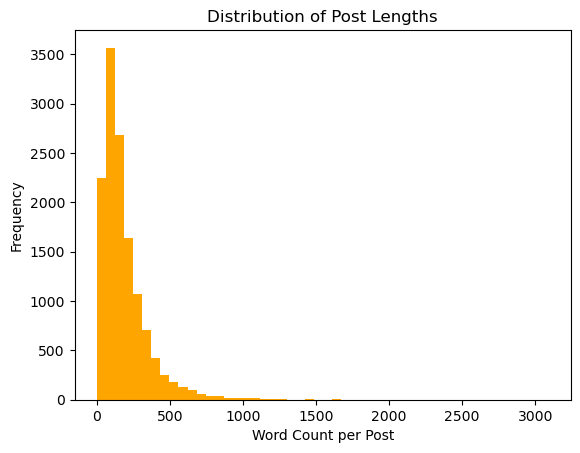

Average post length: 187.0504805873004


In [188]:
plt.hist(df5['n_words'], bins=50, color='orange')
plt.title("Distribution of Post Lengths")
plt.xlabel("Word Count per Post")
plt.ylabel("Frequency")
plt.show()

print("Average post length:", df5['n_words'].mean())


Top 10 words by average TF-IDF score:
tfidf_anxieti    0.159875
tfidf_feel       0.088627
tfidf_like       0.071982
tfidf_get        0.071200
tfidf_go         0.061709
tfidf_attack     0.052176
tfidf_anxious    0.050828
tfidf_know       0.050670
tfidf_work       0.048718
tfidf_time       0.047654
dtype: float64


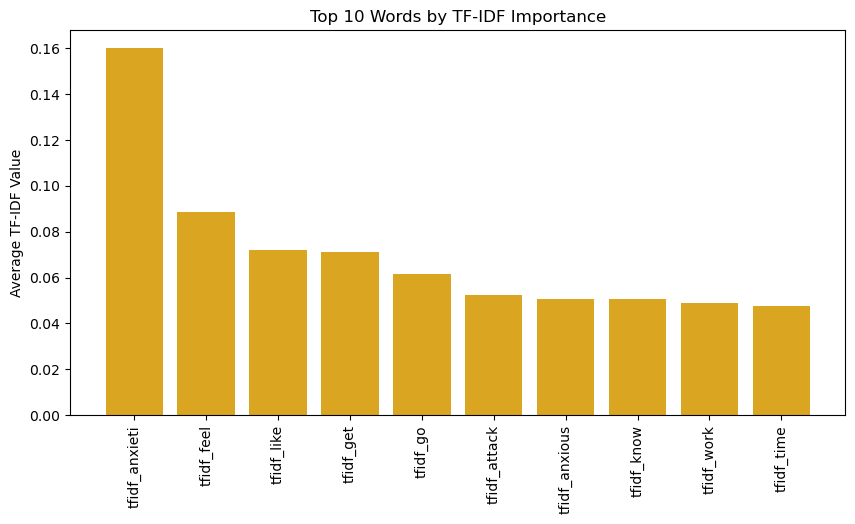

In [189]:
tfidf_cols = [col for col in df5.columns if col.startswith('tfidf_')]

tfidf_mean = df5[tfidf_cols].mean().sort_values(ascending=False)

print("\nTop 10 words by average TF-IDF score:")
print(tfidf_mean.head(10))

top_tfidf = tfidf_mean.head(10)
plt.figure(figsize=(10,5))
plt.bar(top_tfidf.index, top_tfidf.values, color='goldenrod')
plt.title("Top 10 Words by TF-IDF Importance")
plt.xticks(rotation=90)
plt.ylabel("Average TF-IDF Value")
plt.show()



Correlation matrix of readability metrics:
                             automated_readability_index  coleman_liau_index  \
automated_readability_index                     1.000000            0.885010   
coleman_liau_index                              0.885010            1.000000   
flesch_kincaid_grade_level                      0.920037            0.719880   
flesch_reading_ease                            -0.860027           -0.851959   
gulpease_index                                 -0.840105           -0.696341   
gunning_fog_index                               0.775514            0.548741   
smog_index                                      0.671837            0.549403   

                             flesch_kincaid_grade_level  flesch_reading_ease  \
automated_readability_index                    0.920037            -0.860027   
coleman_liau_index                             0.719880            -0.851959   
flesch_kincaid_grade_level                     1.000000            -0.90000

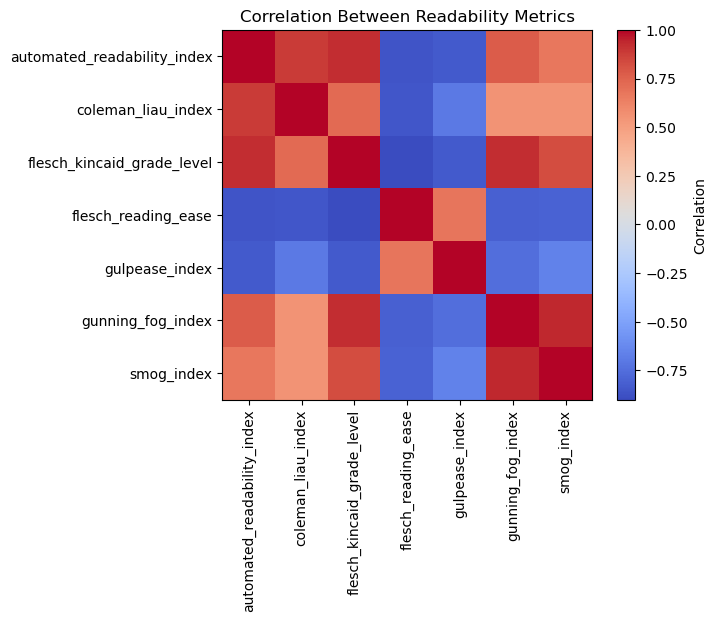

In [190]:
corr_matrix = df5[read_cols].corr()
print("\nCorrelation matrix of readability metrics:")
print(corr_matrix)

plt.imshow(corr_matrix, cmap='coolwarm', interpolation='nearest')
plt.colorbar(label='Correlation')
plt.xticks(range(len(read_cols)), read_cols, rotation=90)
plt.yticks(range(len(read_cols)), read_cols)
plt.title("Correlation Between Readability Metrics")
plt.show()

## JOKES SUBREDDIT 2019

In [191]:
df6 = pd.read_csv("jokes_2019_features_tfidf_256.csv")

In [192]:
print(df6.describe())
print(df6.isnull().sum())

       automated_readability_index  coleman_liau_index  \
count                 28199.000000        28199.000000   
mean                      2.320646            4.084231   
std                       4.167050            4.255668   
min                     -11.295000          -63.262668   
25%                       0.086584            2.043202   
50%                       1.998750            4.094020   
75%                       4.067913            6.125570   
max                     196.052500          245.805559   

       flesch_kincaid_grade_level  flesch_reading_ease  gulpease_index  \
count                28199.000000         28199.000000    28199.000000   
mean                     3.100327            89.732050       87.611854   
std                      3.001799            15.688967       20.651802   
min                     -3.616667          -615.475000     -325.000000   
25%                      1.468077            82.475000       75.000000   
50%                      2.856667

In [193]:
print(df6.shape)
num_posts = len(df6)
print("Number of posts:", num_posts)

(28199, 350)
Number of posts: 28199


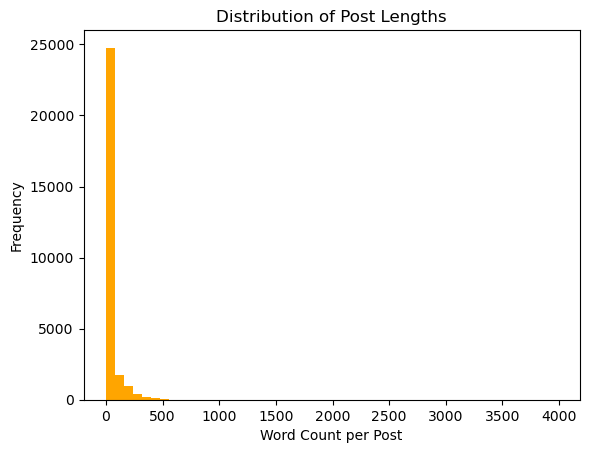

Average post length: 43.684776055888506


In [194]:
plt.hist(df6['n_words'], bins=50, color='orange')
plt.title("Distribution of Post Lengths")
plt.xlabel("Word Count per Post")
plt.ylabel("Frequency")
plt.show()

print("Average post length:", df6['n_words'].mean())


Top 10 words by average TF-IDF score:
tfidf_whi       0.067538
tfidf_say       0.061524
tfidf_call      0.050155
tfidf_ask       0.042655
tfidf_one       0.039385
tfidf_get       0.035909
tfidf_said      0.033936
tfidf_becaus    0.030652
tfidf_guy       0.025281
tfidf_like      0.025196
dtype: float64


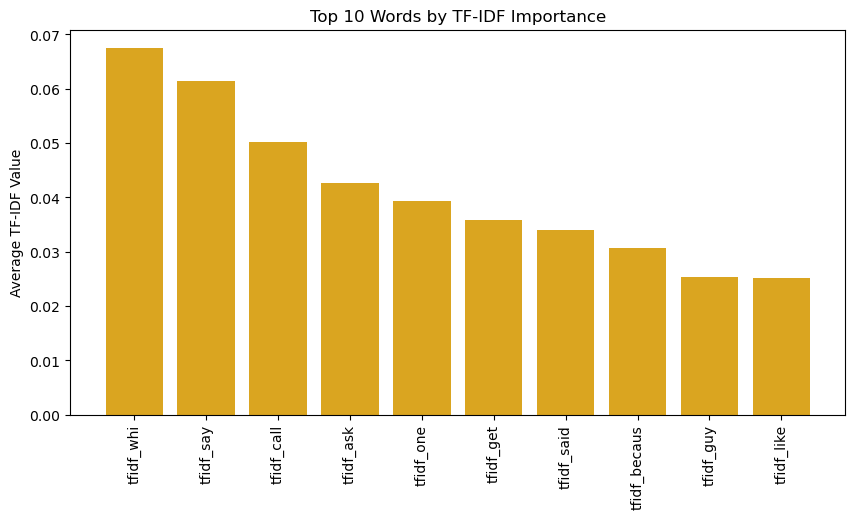

In [195]:
tfidf_cols = [col for col in df6.columns if col.startswith('tfidf_')]

tfidf_mean = df6[tfidf_cols].mean().sort_values(ascending=False)

print("\nTop 10 words by average TF-IDF score:")
print(tfidf_mean.head(10))

top_tfidf = tfidf_mean.head(10)
plt.figure(figsize=(10,5))
plt.bar(top_tfidf.index, top_tfidf.values, color='goldenrod')
plt.title("Top 10 Words by TF-IDF Importance")
plt.xticks(rotation=90)
plt.ylabel("Average TF-IDF Value")
plt.show()


Correlation matrix of readability metrics:
                             automated_readability_index  coleman_liau_index  \
automated_readability_index                     1.000000            0.845523   
coleman_liau_index                              0.845523            1.000000   
flesch_kincaid_grade_level                      0.900695            0.688728   
flesch_reading_ease                            -0.815331           -0.777472   
gulpease_index                                 -0.585043           -0.667974   
gunning_fog_index                               0.722771            0.488958   
smog_index                                      0.533857            0.468120   

                             flesch_kincaid_grade_level  flesch_reading_ease  \
automated_readability_index                    0.900695            -0.815331   
coleman_liau_index                             0.688728            -0.777472   
flesch_kincaid_grade_level                     1.000000            -0.90094

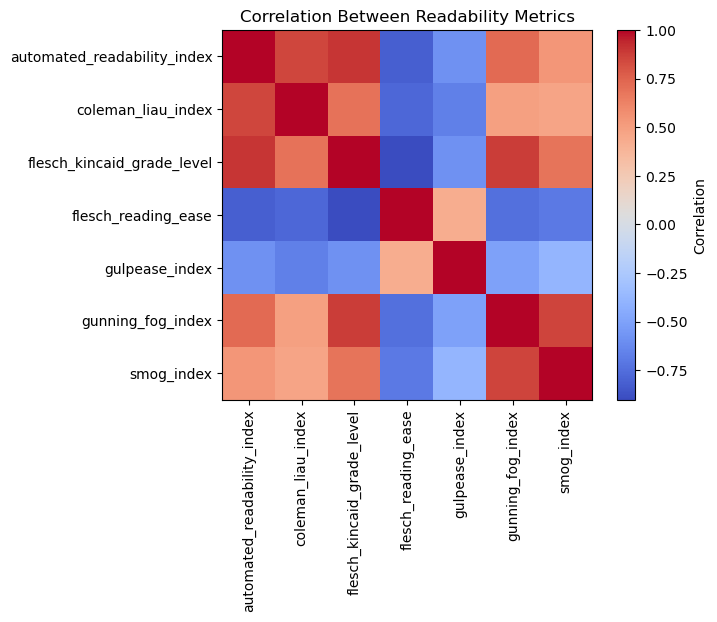

In [196]:
corr_matrix = df6[read_cols].corr()
print("\nCorrelation matrix of readability metrics:")
print(corr_matrix)

plt.imshow(corr_matrix, cmap='coolwarm', interpolation='nearest')
plt.colorbar(label='Correlation')
plt.xticks(range(len(read_cols)), read_cols, rotation=90)
plt.yticks(range(len(read_cols)), read_cols)
plt.title("Correlation Between Readability Metrics")
plt.show()

## Combined EDA

In [201]:
reddit_datasets = {
    'addiction': pd.read_csv('addiction_2019_features_tfidf_256.csv'),
    'adhd': pd.read_csv('adhd_2019_features_tfidf_256.csv'),
    'alcoholism': pd.read_csv('alcoholism_2019_features_tfidf_256.csv'),
    'anxiety': pd.read_csv('anxiety_2019_features_tfidf_256.csv'),
    'jokes': pd.read_csv('jokes_2019_features_tfidf_256.csv'),
    'mentalhealth': pd.read_csv('mentalhealth_2019_features_tfidf_256.csv')
}

for name, df in reddit_datasets.items():
    df['subreddit_name'] = name

combined_df = pd.concat(reddit_datasets.values(), ignore_index=True)

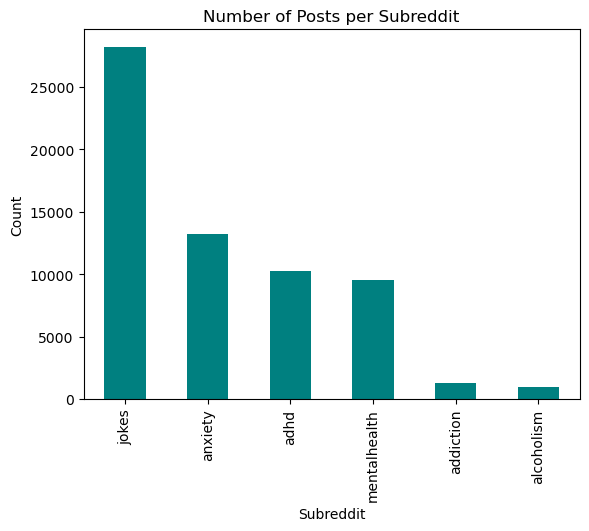

In [202]:
combined_df['subreddit_name'].value_counts().plot(kind='bar', color='teal')
plt.title("Number of Posts per Subreddit")
plt.xlabel("Subreddit")
plt.ylabel("Count")
plt.show()


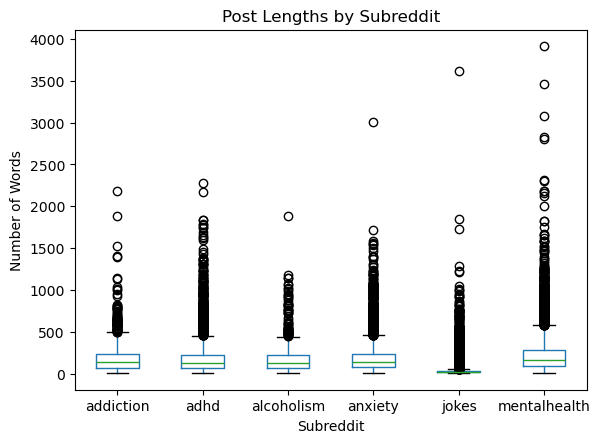

In [203]:
combined_df['post_length'] = combined_df['post'].apply(lambda x: len(str(x).split()))
combined_df.boxplot(column='post_length', by='subreddit_name', grid=False)
plt.title("Post Lengths by Subreddit")
plt.xlabel("Subreddit")
plt.ylabel("Number of Words")
plt.suptitle("")
plt.show()


In [204]:
read_cols = ['automated_readability_index','coleman_liau_index',
             'flesch_kincaid_grade_level','flesch_reading_ease',
             'gulpease_index','gunning_fog_index','smog_index']

# Mean readability per subreddit
readability_by_sub = combined_df.groupby('subreddit_name')[read_cols].mean()
print(readability_by_sub)


                automated_readability_index  coleman_liau_index  \
subreddit_name                                                    
addiction                          4.122960            5.789481   
adhd                               4.495216            5.952892   
alcoholism                         3.265905            4.958765   
anxiety                            3.931729            5.346417   
jokes                              2.320646            4.084231   
mentalhealth                       4.468029            5.889607   

                flesch_kincaid_grade_level  flesch_reading_ease  \
subreddit_name                                                    
addiction                         4.768566            82.461576   
adhd                              5.363987            79.599805   
alcoholism                        4.285942            85.191070   
anxiety                           4.982914            82.085631   
jokes                             3.100327            89.7320

In [205]:
from collections import Counter
import re

def top_words(df, n=10):
    all_words = " ".join(df['post'].astype(str)).lower()
    all_words = re.findall(r'\b\w+\b', all_words)
    return Counter(all_words).most_common(n)

for sub in combined_df['subreddit_name'].unique():
    print(f"\nTop words in {sub}:")
    print(top_words(combined_df[combined_df['subreddit_name']==sub]))



Top words in addiction:
[('i', 15631), ('to', 7976), ('and', 7659), ('the', 5378), ('a', 5236), ('my', 4316), ('it', 4196), ('of', 3603), ('that', 2683), ('for', 2612)]

Top words in adhd:
[('i', 119270), ('to', 59193), ('and', 54894), ('the', 43639), ('a', 39408), ('my', 36847), ('it', 32090), ('of', 27508), ('that', 21787), ('in', 20386)]

Top words in alcoholism:
[('i', 11547), ('to', 5558), ('and', 5159), ('a', 4114), ('the', 3873), ('my', 3074), ('it', 2473), ('of', 2453), ('t', 1840), ('that', 1808)]

Top words in anxiety:
[('i', 172086), ('to', 77992), ('and', 75947), ('the', 53339), ('a', 51379), ('my', 50950), ('it', 42445), ('of', 35576), ('t', 27487), ('that', 27459)]

Top words in jokes:
[('the', 68076), ('a', 44608), ('and', 30980), ('to', 29703), ('i', 29270), ('you', 19599), ('he', 16624), ('it', 15302), ('of', 14898), ('in', 14494)]

Top words in mentalhealth:
[('i', 156891), ('to', 72973), ('and', 69520), ('a', 46410), ('the', 45973), ('my', 44488), ('it', 34384), ('o

In [206]:
tfidf_cols = [col for col in combined_df.columns if col.startswith('tfidf_')]

for sub in combined_df['subreddit_name'].unique():
    subset = combined_df[combined_df['subreddit_name']==sub]
    top_tfidf = subset[tfidf_cols].mean().sort_values(ascending=False).head(10)
    print(f"\nTop TF-IDF words for {sub}:")
    print(top_tfidf)



Top TF-IDF words for addiction:
tfidf_addict    0.214672
tfidf_drug      0.076950
tfidf_day       0.067528
tfidf_get       0.065629
tfidf_use       0.061273
tfidf_help      0.060815
tfidf_year      0.059968
tfidf_know      0.054922
tfidf_time      0.053812
tfidf_want      0.053110
dtype: float64

Top TF-IDF words for adhd:
tfidf_adhd     0.171457
tfidf_get      0.071245
tfidf_take     0.063267
tfidf_like     0.062595
tfidf_work     0.061374
tfidf_feel     0.053875
tfidf_time     0.052803
tfidf_medic    0.052461
tfidf_thing    0.048783
tfidf_med      0.048057
dtype: float64

Top TF-IDF words for alcoholism:
tfidf_drink      0.256658
tfidf_alcohol    0.167938
tfidf_day        0.074951
tfidf_get        0.056835
tfidf_go         0.056533
tfidf_year       0.055638
tfidf_feel       0.053029
tfidf_know       0.052277
tfidf_want       0.050954
tfidf_time       0.050788
dtype: float64

Top TF-IDF words for anxiety:
tfidf_anxieti    0.159875
tfidf_feel       0.088627
tfidf_like       0.071982
t

## RANDOM DATASET

In [161]:
dr = pd.read_csv("Combined Data.csv")

The following data is the status according to a statement.

In [162]:
dr.head(10)

,Unnamed: 0,statement,status
0,0,oh my gosh,Anxiety
1,1,"trouble sleeping, confused mind, restless hear...",Anxiety
2,2,"All wrong, back off dear, forward doubt. Stay ...",Anxiety
3,3,I've shifted my focus to something else but I'...,Anxiety
4,4,"I'm restless and restless, it's been a month n...",Anxiety
5,5,"every break, you must be nervous, like somethi...",Anxiety
6,6,"I feel scared, anxious, what can I do? And may...",Anxiety
7,7,Have you ever felt nervous but didn't know why?,Anxiety
8,8,"I haven't slept well for 2 days, it's like I'm...",Anxiety
9,9,"I'm really worried, I want to cry.",Anxiety


In [166]:
dr["statement"] = dr["statement"].apply(lambda x: len(str(x).split()))
avg_word_count = dr["statement"].mean()
print("Average word count per posts:",round(avg_word_count,2))

Average word count per posts: 112.39


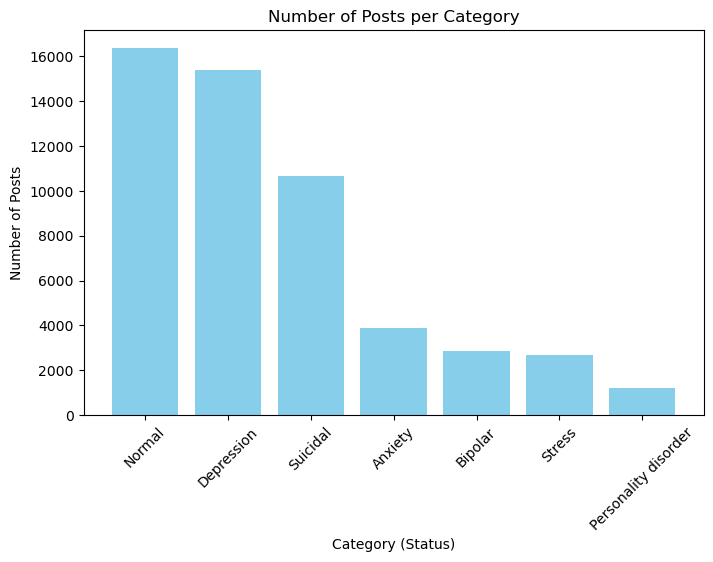

status
Normal                  16351
Depression              15404
Suicidal                10653
Anxiety                  3888
Bipolar                  2877
Stress                   2669
Personality disorder     1201
Name: count, dtype: int64


In [164]:
status_counts = dr['status'].value_counts()

plt.figure(figsize=(8,5))
plt.bar(status_counts.index, status_counts.values, color='skyblue')
plt.title("Number of Posts per Category")
plt.xlabel("Category (Status)")
plt.ylabel("Number of Posts")
plt.xticks(rotation=45)
plt.show()

print(status_counts)

In [167]:
dr.describe()

,Unnamed: 0,statement,word_count
count,53043.000000,53043.000000,53043.000000
mean,26521.000000,112.393285,112.393285
std,15312.339501,163.436684,163.436684
min,0.000000,1.000000,1.000000
25%,13260.500000,15.000000,15.000000
50%,26521.000000,61.000000,61.000000
75%,39781.500000,147.500000,147.500000
max,53042.000000,6300.000000,6300.000000


## ANOTHER DATASET TWITTER

In [83]:
df2 = pd.read_csv("datatwitter.json")

In [95]:
with open('datatwitter.json', 'r') as f:
    data = json.load(f)


In [106]:
print(type(data))

<class 'dict'>


In [107]:
print("Keys in the JSON file:")
print(list(data.keys()))

Keys in the JSON file:
['dcterms:title', 'dcterms:accessRights', 'dcterms:creator', 'dcterms:description', 'dcterms:issued', 'dcterms:language', 'dcterms:identifier', 'dcat:theme', 'dcterms:type', 'dcat:keyword', 'dcat:landingPage', 'dcterms:hasVersion', 'dcterms:format', 'mls:task', 'datacite:isDescribedBy']


In [108]:
for key, value in data.items():
    print(f"\n{key}: {value}")


dcterms:title: CLPsych 2015 Shared Task: Depression and PTSD on Twitter

dcterms:accessRights: 

dcterms:creator: ['Moin Nadeem', 'Mike Horn', 'Glen Coppersmith', 'Johns Hopkins University', 'Dr. Sandip Sen']

dcterms:description: A dataset created by Coppersmith et al. for the Computational Linguistics and Clinical Psychology (CLPsych) 2015 Shared Task.

dcterms:issued: 2015

dcterms:language: English

dcterms:identifier: 

dcat:theme: ['Mental Health', 'Social Media', 'Depression']

dcterms:type: ['Dataset']

dcat:keyword: ['Mental Health', 'Social Media', 'Twitter', 'Depression']

dcat:landingPage: https://www.clpsych2015.org/

dcterms:hasVersion: 

dcterms:format: Text

mls:task: ['Depression Detection', 'Mental Health Diagnosis']

datacite:isDescribedBy: ['10.48550/arXiv.1607.07384']


In [109]:
df2 = pd.DataFrame([data])
df2.head()

,dcterms:title,dcterms:accessRights,dcterms:creator,dcterms:description,dcterms:issued,dcterms:language,dcterms:identifier,dcat:theme,dcterms:type,dcat:keyword,dcat:landingPage,dcterms:hasVersion,dcterms:format,mls:task,datacite:isDescribedBy
0,CLPsych 2015 Shared Task: Depression and PTSD ...,,"[Moin Nadeem, Mike Horn, Glen Coppersmith, Joh...",A dataset created by Coppersmith et al. for th...,2015,English,,"[Mental Health, Social Media, Depression]",[Dataset],"[Mental Health, Social Media, Twitter, Depress...",https://www.clpsych2015.org/,,Text,"[Depression Detection, Mental Health Diagnosis]",[10.48550/arXiv.1607.07384]


In [111]:
# Shape
print("Shape:", df2.shape)

# Column names
print("\nColumns:\n", df2.columns.tolist())

# Data types
print("\nData types:\n", df2.dtypes)

# Missing values
print("\nMissing values:\n", df2.isnull().sum())

# Summary
print("\nSummary stats (non-numeric columns won't show much):\n")
print(df2.describe(include='all'))


Shape: (1, 15)

Columns:
 ['dcterms:title', 'dcterms:accessRights', 'dcterms:creator', 'dcterms:description', 'dcterms:issued', 'dcterms:language', 'dcterms:identifier', 'dcat:theme', 'dcterms:type', 'dcat:keyword', 'dcat:landingPage', 'dcterms:hasVersion', 'dcterms:format', 'mls:task', 'datacite:isDescribedBy']

Data types:
 dcterms:title             object
dcterms:accessRights      object
dcterms:creator           object
dcterms:description       object
dcterms:issued            object
dcterms:language          object
dcterms:identifier        object
dcat:theme                object
dcterms:type              object
dcat:keyword              object
dcat:landingPage          object
dcterms:hasVersion        object
dcterms:format            object
mls:task                  object
datacite:isDescribedBy    object
dtype: object

Missing values:
 dcterms:title             0
dcterms:accessRights      0
dcterms:creator           0
dcterms:description       0
dcterms:issued            0
dcter

In [113]:
# Example: creators
creators = df2.loc[0, 'dcterms:creator']
print("Creators:", ", ".join(creators))

# Example: keywords
keywords = df2.loc[0, 'dcat:keyword']
print("Keywords:", ", ".join(keywords))


Creators: Moin Nadeem, Mike Horn, Glen Coppersmith, Johns Hopkins University, Dr. Sandip Sen
Keywords: Mental Health, Social Media, Twitter, Depression
